# Demo 4 — coded-aperture holography (2-D)

**One** propagation distance through a **2-D** object, with a gold coded
aperture in the beam, then joint recovery of **object**, **aperture** and
**both position sets** with the Bilinear-Hessian solver.

The 2-D sibling of [demo 3](03_coded_holotomography.ipynb). Same beam, same
geometry, same aperture, same solver family — the sample is one plane rather
than a volume, so there is no tomography, no angles, and no Paganin+FBP start.
The scan axis is **frames**, each with its own object shift and its own code
shift.

As in demo 3, the mask moves from frame to frame, so every frame sees a
different speckle pattern through the same object. That diversity is what one
distance otherwise lacks.

Everything is written out here; the notebook imports nothing but the package
itself. One GPU, about a minute.

In [1]:
import os, sys
sys.path.insert(0, os.path.abspath('..') + '/src')
from types import SimpleNamespace
import numpy as np
import cupy as cp
import matplotlib.pyplot as plt
from scipy.fft import fft2, ifft2, fftshift
from mpi4py import MPI
from holotomocupy.logger_config import set_log_level

set_log_level('INFO')
comm = MPI.COMM_WORLD        # one rank here; the .py next door runs the same on N
print('GPU:', cp.cuda.runtime.getDeviceProperties(0)['name'].decode())

GPU: NVIDIA A100-SXM4-40GB


## Geometry

The ESRF single-coded-aperture setting, as in demo 3. The code sits **upstream
of the focal spot**, so `Z_CODE` is negative and the code → sample Fresnel
distance comes out negative too.

One shared index grid, a different physical pixel size at each plane. The
`alias margin` is how much larger the grid is than the smallest alias-free
one. `Propagation` pads `n → 2n`, so a margin above about 2 means that padding
is wider than the physics needs.

In [2]:
ENERGY   = 33.35                      # keV
DET_PIX0 = 3 * 1.01250442970688e-6    # NATIVE detector pixel [m]
CROP     = 2048                       # full detector width [native px]
Z_CODE   = -18e-3                     # focus -> code (NEGATIVE: upstream of the focus)
Z_SAMPLE = 4.214e-3                   # focus -> sample
Z_DET    = 1.28                       # focus -> detector

n        = 512                        # detector size used here
nframes  = 64                         # scan frames
niter    = 257                        # BH iterations

ratio     = CROP // n
det_px    = DET_PIX0 * ratio
voxelsize = det_px * Z_SAMPLE / Z_DET          # sample-plane pixel
code_px   = abs(det_px * Z_CODE / Z_DET)       # aperture-plane pixel
wavelength = 1.24e-09 / ENERGY

# parallel-beam-equivalent Fresnel distances, reference plane = sample
d1 = Z_SAMPLE**2 * (1 / Z_CODE   - 1 / Z_SAMPLE)    # code -> sample
d2 = Z_SAMPLE**2 * (1 / Z_SAMPLE - 1 / Z_DET)       # sample -> detector

OBJ_MARGIN = 64                       # nobj = n + this, absorbs the object shift
OBJ_JITTER = 30.0                     # object shift range [px], +- half
nobj    = n + OBJ_MARGIN
scan_px = int(np.ceil(n / 8))         # code shift, +- this
q       = max(64, n // 8)
ncode   = int(np.ceil((n + 2 * scan_px + 32) / q) * q)

alias = min(n / (wavelength * abs(d) / voxelsize**2) for d in (d1, d2))
print(f'n={n}  nobj={nobj}  ncode={ncode}  frames={nframes}  code scan +-{scan_px}px')
print(f'pixel size:  code {code_px*1e9:.1f} nm   sample {voxelsize*1e9:.1f} nm   det {det_px*1e9:.1f} nm')
print(f'D_eff:  code->sample {d1*1e3:.4f} mm   sample->det {d2*1e3:.4f} mm')
print(f'alias margin {alias:.2f}x')

n=512  nobj=576  ncode=704  frames=64  code scan +-64px
pixel size:  code 170.9 nm   sample 40.0 nm   det 12150.1 nm
D_eff:  code->sample -5.2005 mm   sample->det 4.2001 mm
alias margin 4.24x


## The phantom

A Siemens star as a **weak phase object**, phase range `[0, pi/8]`, smoothed so
it is band-limited on this grid. `delta_beta = 29` sets the absorption, which
is 3.4% of the phase and is not what the recovery is scored on.

In [3]:
def siemens_star(nobj, step_deg=15):
    """(nobj, nobj) float32 Siemens-star mask, spokes every step_deg."""
    def rotate(pts, ang, c):
        s, co_ = np.sin(ang), np.cos(ang)
        return (pts - c) @ np.array([[co_, -s], [s, co_]], 'float32').T + c

    def tri(X, Y, t):
        (x1, y1), (x2, y2), (x3, y3) = t
        d = (y2 - y3) * (x1 - x3) + (x3 - x2) * (y1 - y3)
        if d == 0:
            return np.zeros_like(X, dtype=bool)
        a = ((y2 - y3) * (X - x3) + (x3 - x2) * (Y - y3)) / d
        b = ((y3 - y1) * (X - x3) + (x1 - x3) * (Y - y3)) / d
        return (a >= 0) & (b >= 0) & (1 - a - b >= 0)

    t0 = np.array([(1.5 * nobj // 16, nobj // 2 - nobj // 32),
                   (1.5 * nobj // 16, nobj // 2 + nobj // 32),
                   (nobj // 2 - nobj // 128, nobj // 2)], dtype='float32')
    yy, xx = np.mgrid[0:nobj, 0:nobj]
    c = np.array([nobj / 2, nobj / 2], dtype='float32')
    star = np.zeros((nobj, nobj), dtype='float32')
    for deg in range(0, 360, step_deg):
        star += tri(xx, yy, rotate(t0, np.deg2rad(deg), c)).astype('float32')
    return star / (star.max() or 1.0)


def star_projection(nobj, delta_beta=29.0, smooth=8.0):
    """complex64 (nobj, nobj): the star as a transmission, -delta + i*beta."""
    star = siemens_star(nobj)
    v = np.arange(-nobj // 2, nobj // 2, dtype='float32') / nobj
    vx, vy = np.meshgrid(v, v, indexing='ij')
    g = fftshift(np.exp(-smooth * (vx**2 + vy**2)).astype('float32'))
    star = ifft2(fft2(star) * g).real
    star = star / star.max() * (np.pi / 8)          # phase range [0, pi/8]
    return (-star + 1j * star / delta_beta).astype('complex64')

## The coded aperture

Random squares of gold on a 45°-rotated lattice. Three details matter, and all
three are easy to get wrong:

* **it is built on the aperture's own pixel size**, not the sample voxel. The
  two differ by `|Z_CODE| / Z_SAMPLE` here, so using the voxel would misstate
  the fabricated cell size by more than 4x.
* **the transmission is real gold**, `exp(i·k·(−δ + iβ)·t·pattern)`. Contrast
  goes as `2|sin(φ/2)|` and so *peaks* at the thickness giving π, which is
  6.49 µm of Au at 33.35 keV. The 3 µm used here is a realistic mask rather
  than the best possible one.
* **the lattice is hashed directly in rotated coordinates**, so rotating costs
  no interpolation, and supersampling antialiases the cell edges.

δ and β are pinned below rather than taken from `xraylib`, which is not a
dependency of this package.

In [4]:
# delta, beta for Au (19.3 g/cm^3) at 33.35 keV, from xraylib.
AU_DELTA, AU_BETA = 2.863698e-06, 1.190692e-07

def _hash_bits(iu, iv, seed):
    """Deterministic 0/1 per integer cell index (splitmix64 finalizer), so
    the pattern can be built directly in rotated coordinates."""
    u64 = np.uint64
    seed_term = u64((seed & 0xFFFFFFFF) * 0x165667B19E3779F9 % (1 << 64))
    h = (iu.astype(u64) * u64(0x9E3779B97F4A7C15)) ^ \
        (iv.astype(u64) * u64(0xC2B2AE3D27D4EB4F)) ^ seed_term
    h ^= h >> u64(30); h *= u64(0xBF58476D1CE4E5B9)
    h ^= h >> u64(27); h *= u64(0x94D049BB133111EB)
    h ^= h >> u64(31)
    return (h & u64(1)).astype(np.float32)


def code_pattern(n, feature_m, pixel_size_m, angle_deg=45.0, seed=0, supersample=2):
    """(n, n) float32 fill fraction per pixel of a random square lattice."""
    s = max(1, int(supersample))
    w = float(feature_m) / float(pixel_size_m)       # cell side, in pixels
    th = np.deg2rad(angle_deg)
    ct, st = np.cos(th), np.sin(th)
    sub = (np.arange(s, dtype=np.float64) + 0.5) / s - 0.5
    grid = np.arange(n, dtype=np.float64) - n / 2.0 + 0.5
    xs = (grid[:, None] + sub[None, :]).ravel()
    Y, X = np.meshgrid(xs, xs, indexing='ij')
    u = (X * ct + Y * st) / w
    v = (-X * st + Y * ct) / w
    bits = _hash_bits(np.floor(u).astype(np.int64), np.floor(v).astype(np.int64), seed)
    return bits.reshape(n, s, n, s).mean(axis=(1, 3)).astype(np.float32)


def coded_aperture(n, feature_m, pixel_size_m, thickness_m, energy_kev,
                   angle_deg=45.0, seed=0, supersample=2):
    """complex64 (n, n): exp(i*k*(-delta + i*beta)*t*pattern)."""
    pattern = code_pattern(n, feature_m, pixel_size_m, angle_deg, seed, supersample)
    k = 2 * np.pi / (1.24e-09 / energy_kev)
    return np.exp(1j * k * pattern * (-AU_DELTA + 1j * AU_BETA)
                  * float(thickness_m)).astype('complex64')


def thickness_for_phase(phase_rad, energy_kev):
    k = 2 * np.pi / (1.24e-09 / energy_kev)
    return phase_rad / (k * AU_DELTA)

In [5]:
def zoom(a, f=4):
    """The central 1/f of a 2-D array: the texture, not the support ring."""
    h, w = a.shape
    dh, dw = h // (2 * f), w // (2 * f)
    return a[h // 2 - dh:h // 2 + dh, w // 2 - dw:w // 2 + dw]


def panels(items, zoom_factor=4, cmap='gray', vref=None, shared=True):
    """Each item as (full frame, {f}x zoom).

    shared=True puts every panel on ONE grey scale, taken from `vref` or from
    the last item. That is what you want when comparing like with like -- two
    reconstructions of the same thing, or the same frame with and without the
    mask.

    shared=False gives each panel its own scale. Use it whenever the panels
    are different PHYSICAL quantities, or when one of them is a difference.
    A shared scale there silently saturates the others to flat white: the
    object phase spans [0, 0.39] rad and the aperture phase [-1.45, 0], so on
    the aperture's scale the object is entirely above vmax and vanishes.
    """
    ref = vref if vref is not None else items[-1][1]
    g_lo, g_hi = np.percentile(ref, [0.5, 99.5])
    fig, ax = plt.subplots(2, len(items), figsize=(4.6 * len(items), 9.0),
                           squeeze=False)
    for k, (lab, img) in enumerate(items):
        vmin, vmax = (g_lo, g_hi) if shared else np.percentile(img, [0.5, 99.5])
        rng = '' if shared else f'\n[{vmin:+.3g}, {vmax:+.3g}]'
        im = ax[0][k].imshow(img, cmap=cmap, vmin=vmin, vmax=vmax)
        ax[0][k].set_title(lab + rng)
        ax[1][k].imshow(zoom(img, zoom_factor), cmap=cmap, vmin=vmin, vmax=vmax)
        ax[1][k].set_title(f'{lab} - {zoom_factor}x centre')
        for r in (0, 1):
            ax[r][k].axis('off')
        if not shared:
            fig.colorbar(im, ax=[ax[0][k], ax[1][k]], fraction=0.035)
    fig.tight_layout()

## Truth

The object, the aperture, and the two position sets. The probe is **flat**, so
the aperture is the only source of illumination diversity and `prb` carries no
error — nothing is asked of it here.

The fabricated cell is **2 µm**, the `params.py` value demo 03 uses. Demo 03
runs at `n = 128`, where that is only 2.93 aperture pixels and the mask is
marginally sampled. Here the aperture pixel is 170.9 nm, so the same 2 µm cell
is **11.7 pixels** and the speckle shows real structure rather than looking
like noise.

aperture cells 2.00 um = 11.71 code px, 3.0 um Au
code phase excursion 1.452 rad  (t_pi = 6.49 um)


/tmp/ipykernel_2730739/2672937109.py:37: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


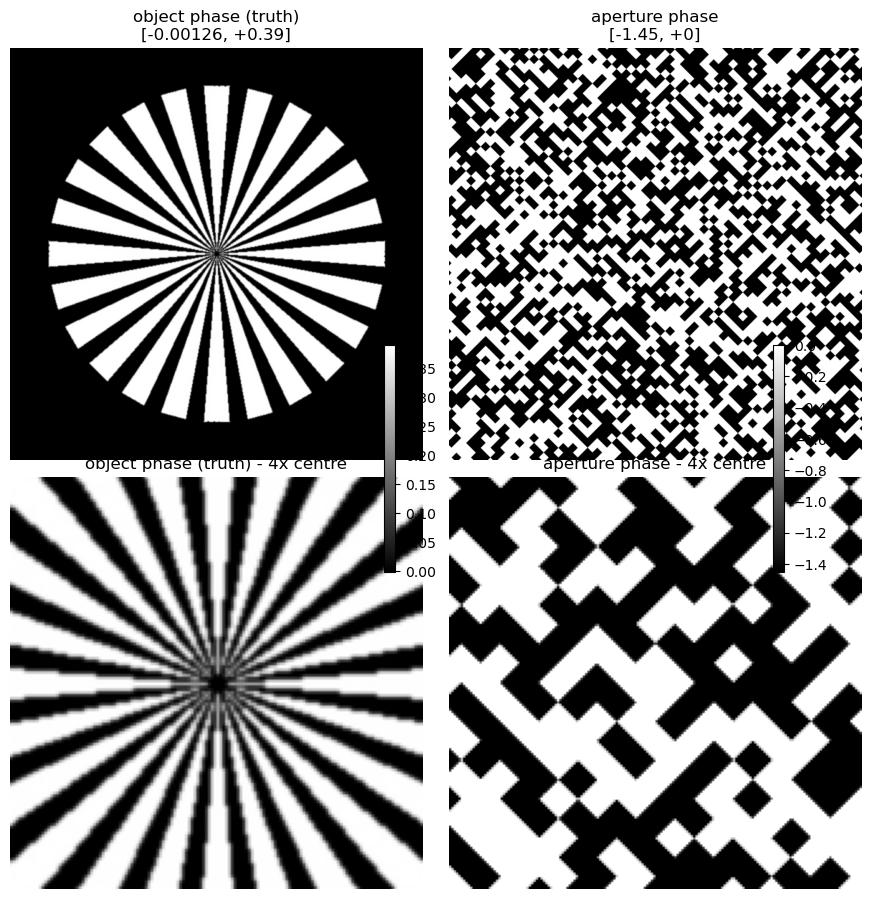

In [6]:
feature_m   = 2.0e-6    # 2 um cells: the params.py value demo 03 uses
thickness_m = 3.0e-6

obj  = star_projection(nobj)
prb  = np.ones((n, n), dtype='complex64')
code = coded_aperture(ncode, feature_m, code_px, thickness_m, ENERGY,
                      angle_deg=45.0, supersample=2)

rng = np.random.default_rng(10)
pos          = (OBJ_JITTER * (rng.random((nframes, 2)) - 0.5)).astype('float32')
pos_err      = (rng.random((nframes, 2)) - 0.5).astype('float32')
pos_code     = rng.uniform(-scan_px, scan_px, (nframes, 2)).astype('float32')
pos_code_err = (rng.random((nframes, 2)) - 0.5).astype('float32')

print(f'aperture cells {feature_m*1e6:.2f} um = {feature_m/code_px:.2f} code px, '
      f'{thickness_m*1e6:.1f} um Au')
print(f'code phase excursion {np.ptp(np.angle(code)):.3f} rad  '
      f'(t_pi = {thickness_for_phase(np.pi, ENERGY)*1e6:.2f} um)')
panels([('object phase (truth)', -obj.real), ('aperture phase', np.angle(code))],
       shared=False)   # different quantities -> separate scales

## Forward: one distance, through the aperture

`RecHoloCoded` holds the whole forward model. `gen_data` writes **intensity**,
`K|psi|^2`, which is what the misfit compares against in both models — the
amplitude model takes its own square root internally.

In [7]:
from holotomocupy.rec_holo_coded_mpi import RecHoloCoded

cl = RecHoloCoded(SimpleNamespace(
    energy=ENERGY, detector_pixelsize=det_px,
    focustodetectordistance=Z_DET, z1=Z_SAMPLE, z1_code=Z_CODE,
    ntheta=nframes, nz=n, n=n, nzobj=nobj, nobj=nobj, ncode=ncode,
    rho=[1, 0.05, 0.02, 0.05, 0.02], code_pad_frac=0.125,
    shift_type='fft', model='amplitude', psf_sigma=0.0,
    freeze_code=False, freeze_pos_code=False,
    niter=niter, nchunk=16, checkpoint_step=-1, error_step=8,
    start_iter=0, comm=comm))

cl.vars['obj'][:]      = cp.asarray(obj)
cl.vars['prb'][:]      = cp.asarray(prb)
cl.vars['code'][:]     = cp.asarray(code)
cl.vars['pos'][:]      = pos
cl.vars['pos_code'][:] = pos_code
cl.gen_data(cl.vars, cl.data)        # INTENSITY
print('data', cl.data.shape, cl.data.dtype,
      'range', float(cl.data.min()), float(cl.data.max()))

/home/beams0/CEKMEKCI/Desktop/holotomocupy/src/holotomocupy/conv2d_cufftdx.py:265: UserWarning: nvcc not found (NVCC='nvcc'). Set NVCC env var or add nvcc to PATH. Falling back to cuPy FFT.
  if cufftdx_available():


2026-11-24 08:00:29 [rank=0] code window: [640, 640] (pad 64, 64) out of a [704, 704] plane, code_pad_frac=0.125


data (64, 512, 512) float32 range 1.985431481443811e-06 4.682854652404785


### What the mask buys

The same object, with and without the aperture. Without it, one distance gives
one contrast transfer function and its zeros are simply missing from the data.
The mask breaks that up — and because it moves, it breaks it up *differently on
every frame*, which is the diversity extra distances would otherwise provide.

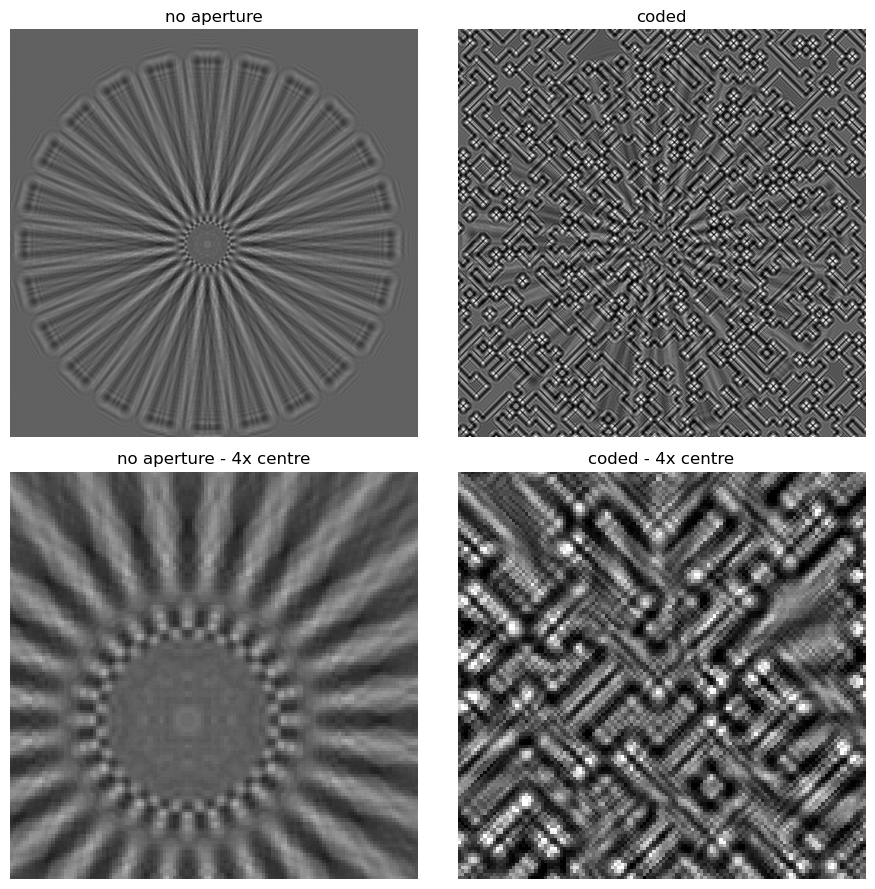

In [8]:
data_coded = np.asarray(cl.data[0]).copy()

cl.vars['code'][:] = 1                  # transparent = plain holography
cl.gen_data(cl.vars, cl.data)
data_plain = np.asarray(cl.data[0]).copy()

cl.vars['code'][:] = cp.asarray(code)   # put it back
cl.gen_data(cl.vars, cl.data)

panels([('no aperture', data_plain), ('coded', data_coded)], zoom_factor=4)

### Two frames, to see the diversity

Consecutive frames differ by a code shift, so the speckle is not the same
pattern twice. This is the whole mechanism.

/tmp/ipykernel_2730739/2672937109.py:37: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


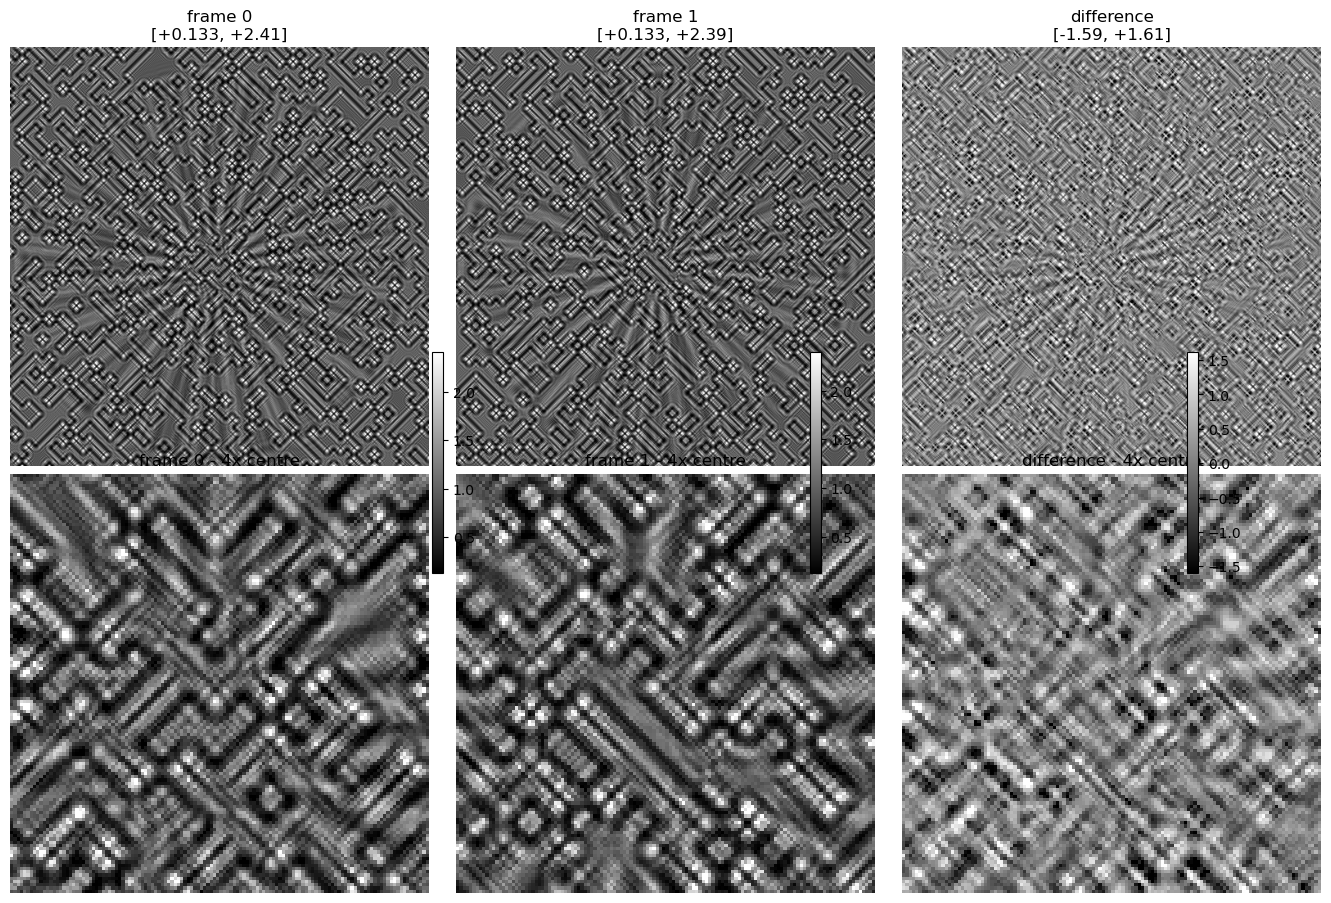

In [9]:
panels([('frame 0', np.asarray(cl.data[0])),
        ('frame 1', np.asarray(cl.data[1])),
        ('difference', np.asarray(cl.data[0]) - np.asarray(cl.data[1]))],
       zoom_factor=4, shared=False)   # the difference is far smaller than the frames

## The starting point

A **cold** object — zero, not a Paganin estimate, since with one 2-D plane
there is no FBP to seed it. The probe is exactly right and stays so. The
aperture starts as the truth plus 2% of its own contrast, which is what a real
run would have after calibrating the mask by near-field ptychography. Both
position sets start off by up to ~0.5 px.

In [10]:
code_err_frac = 0.02
c = float(np.abs(code - code.mean()).std())
code0 = (code + code_err_frac * c
         * (rng.standard_normal(code.shape)
            + 1j * rng.standard_normal(code.shape))).astype('complex64')

cl.vars['obj'][:]      = 0
cl.vars['prb'][:]      = 1
cl.vars['code'][:]     = cp.asarray(code0)
cl.vars['pos'][:]      = pos + pos_err
cl.vars['pos_code'][:] = pos_code + pos_code_err
print('start: object 0, probe exact, code +2% noise, positions off by ~0.5 px')

start: object 0, probe exact, code +2% noise, positions off by ~0.5 px


## Inverse

In [11]:
cl.BH()

2026-11-24 08:00:30 [rank=0] data mask: |pos|<=14.96px margin=2px -> keeps 100.0% of the pixels per angle (min 100.0%, max 100.0%). F0 still divides by the FULL ntheta*nz*n, so reported errors scale with that fraction and are not comparable with an unmasked run.


2026-11-24 08:00:30 [rank=0] Initial err=1.18088e-02 


2026-11-24 08:00:30 [rank=0] iter=0: 0.2835sec (-min=0.2645sec) err=6.89912e-03 |dobj|^2=1.61904e+03 rel=1.000e+00


2026-11-24 08:00:32 [rank=0] iter=8: 1.5630sec (-min=1.5447sec) err=1.30775e-04 |dobj|^2=1.01924e+01 rel=4.139e-02


2026-11-24 08:00:33 [rank=0] iter=16: 1.5637sec (-min=1.5454sec) err=8.11812e-05 |dobj|^2=1.82199e+01 rel=4.850e-02


2026-11-24 08:00:35 [rank=0] iter=24: 1.5609sec (-min=1.5426sec) err=3.75109e-05 |dobj|^2=1.14576e+01 rel=3.627e-02


... (26 outputs left out)

2026-11-24 08:01:17 [rank=0] iter=240: 1.5633sec (-min=1.5450sec) err=1.35338e-08 |dobj|^2=2.23594e-03 rel=4.977e-04


2026-11-24 08:01:19 [rank=0] iter=248: 1.5600sec (-min=1.5417sec) err=1.16946e-08 |dobj|^2=1.68718e-03 rel=4.317e-04


2026-11-24 08:01:20 [rank=0] iter=256: 1.5591sec (-min=1.5407sec) err=1.03587e-08 |dobj|^2=1.26669e-03 rel=3.737e-04


{'obj': array([[-0.00065256+1.7915951e-04j,  0.00064722-1.8675263e-04j,
         -0.0006353 +1.9296784e-04j, ...,  0.00062896-1.5117931e-04j,
         -0.00064352+1.6110066e-04j,  0.0006513 -1.7052235e-04j],
        [ 0.00066293-1.9484648e-04j, -0.00065546+2.0210740e-04j,
          0.00064124-2.0815148e-04j, ..., -0.00064558+1.6801858e-04j,
          0.00065814-1.7751948e-04j, -0.00066382+1.8650129e-04j],
        [-0.00066959+2.0998936e-04j,  0.00065988-2.1717454e-04j,
         -0.00064353+2.2295285e-04j, ...,  0.00065799-1.8427052e-04j,
         -0.00066874+1.9332749e-04j,  0.0006725 -2.0209477e-04j],
        ...,
        [ 0.00059668-1.2885232e-04j, -0.00059823+1.3755173e-04j,
          0.00059348-1.4491874e-04j, ..., -0.00055332+9.6683492e-05j,
          0.00057433-1.0808539e-04j, -0.00058868+1.1892731e-04j],
        [-0.00061955+1.4615800e-04j,  0.00061882-1.5448997e-04j,
         -0.0006116 +1.6138078e-04j, ...,  0.00058313-1.1552491e-04j,
         -0.00060189+1.2656386e-04j,  0.0

## Result

Scored on the region every frame actually illuminates — the central `n x n`
minus the shift range. Outside it the reconstruction is zero by construction
while the phantom is not, so including it would only measure the support.

The correlation is accumulated in **float64**. `np.vdot` on float32 drifts by
~2e-4 over a few million elements, which is enough to report a correlation
above 1.

object corr  0.999683
code   corr  0.999999   (started at 0.999996)
pos      err 0.0203 px (started at 0.2522)
pos_code err 0.0005 px (started at 0.2597)


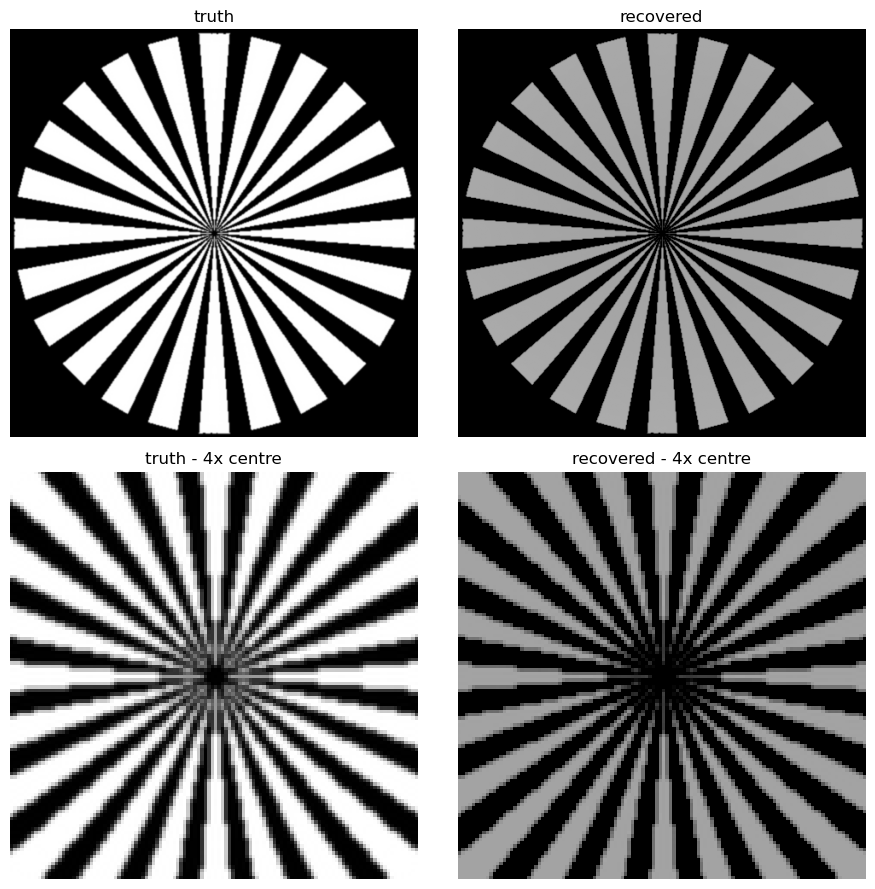

In [12]:
def corr(a, b):
    dt = 'complex128' if np.iscomplexobj(a) or np.iscomplexobj(b) else 'float64'
    a = a.ravel().astype(dt); b = b.ravel().astype(dt)
    a = a - a.mean(); b = b - b.mean()
    d = np.linalg.norm(a) * np.linalg.norm(b)
    return float(np.abs(np.vdot(a, b)) / d) if d else float('nan')

got      = cp.asnumpy(cl.vars['obj'])
code_got = cp.asnumpy(cl.vars['code'])

m  = int(np.ceil(OBJ_JITTER / 2)) + 2
sl = (slice(nobj // 2 - n // 2 + m, nobj // 2 + n // 2 - m),) * 2

print(f'object corr  {corr(got.real[sl], obj.real[sl]):.6f}')
print(f'code   corr  {corr(code_got, code):.6f}   (started at {corr(code0, code):.6f})')
print(f'pos      err {np.abs(np.asarray(cl.vars["pos"]) - pos).mean():.4f} px '
      f'(started at {np.abs(pos_err).mean():.4f})')
print(f'pos_code err {np.abs(np.asarray(cl.vars["pos_code"]) - pos_code).mean():.4f} px '
      f'(started at {np.abs(pos_code_err).mean():.4f})')

panels([('truth', -obj.real[sl]), ('recovered', -got.real[sl])], vref=-obj.real[sl])

### Where the error lives

The difference, on its own scale. A flat field here means the residual is
noise rather than structure. Spokes or a bowl would mean the recovery is
missing something systematic.

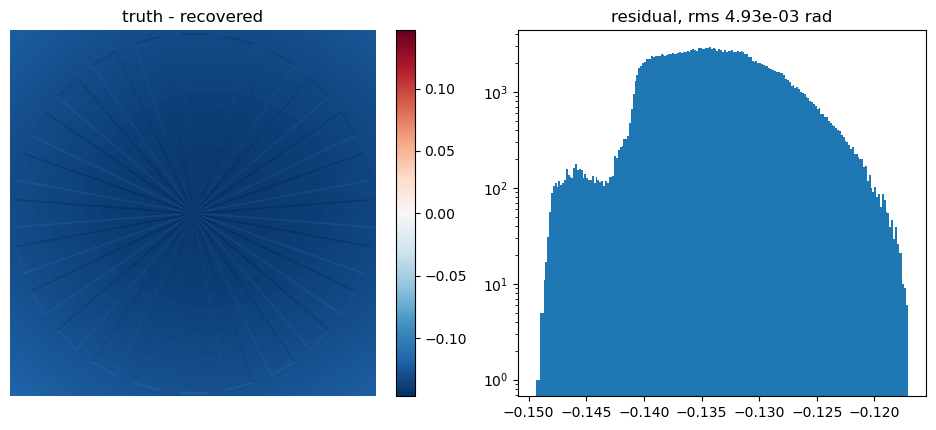

In [13]:
diff = -(got.real[sl] - obj.real[sl])
lim = np.percentile(np.abs(diff), 99.5)
fig, ax = plt.subplots(1, 2, figsize=(9.5, 4.4))
im = ax[0].imshow(diff, cmap='RdBu_r', vmin=-lim, vmax=+lim)
ax[0].set_title('truth - recovered'); ax[0].axis('off')
fig.colorbar(im, ax=ax[0], fraction=0.046)
ax[1].hist(diff.ravel(), bins=200)
ax[1].set_title(f'residual, rms {diff.std():.2e} rad')
ax[1].set_yscale('log')
fig.tight_layout()

### Convergence, and the positions

`cl.table` is the same `conv.csv` the script writes. `|dobj|^2` is the squared
norm of the step, so it falling is the solver settling rather than stalling.

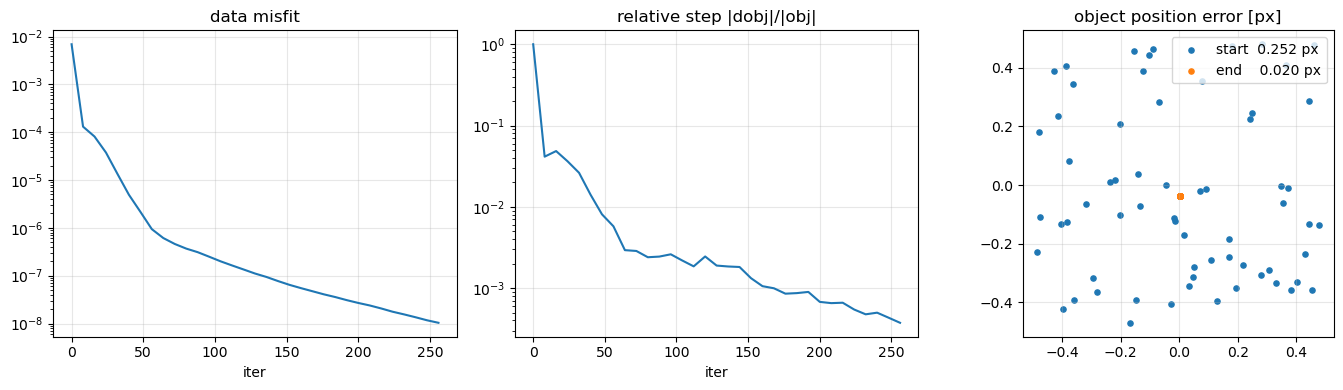

In [14]:
t = cl.table[cl.table['iter'] >= 0]
fig, ax = plt.subplots(1, 3, figsize=(14, 4))
ax[0].semilogy(t['iter'], t['err']); ax[0].set_xlabel('iter')
ax[0].set_title('data misfit'); ax[0].grid(alpha=.3)
ax[1].semilogy(t['iter'], t['dobj_rel']); ax[1].set_xlabel('iter')
ax[1].set_title('relative step |dobj|/|obj|'); ax[1].grid(alpha=.3)

p0 = pos_err
p1 = np.asarray(cl.vars['pos']) - pos
ax[2].scatter(p0[:, 1], p0[:, 0], s=14, label=f'start  {np.abs(p0).mean():.3f} px')
ax[2].scatter(p1[:, 1], p1[:, 0], s=14, label=f'end    {np.abs(p1).mean():.3f} px')
ax[2].set_aspect('equal'); ax[2].grid(alpha=.3)
ax[2].set_title('object position error [px]'); ax[2].legend()
fig.tight_layout()

### The aperture

Refined alongside everything else. It starts close to the truth, so the
interesting panel is the difference rather than the aperture itself.

/tmp/ipykernel_2730739/2672937109.py:37: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


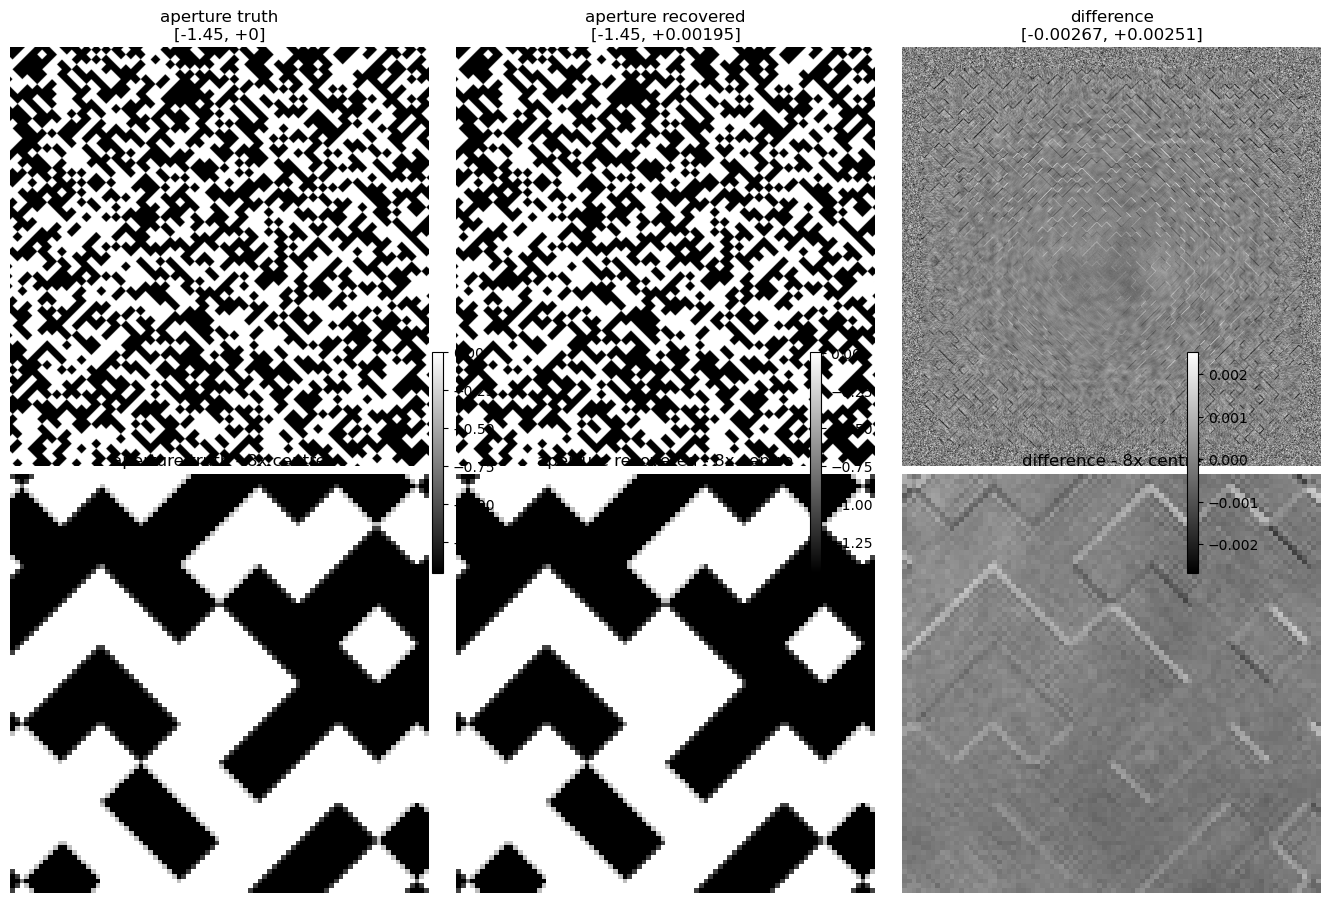

In [15]:
panels([('aperture truth', np.angle(code)),
        ('aperture recovered', np.angle(code_got)),
        ('difference', np.angle(code_got) - np.angle(code))],
       zoom_factor=8, shared=False)   # the difference is ~1e-3 of the aperture

---

**A caveat on these numbers.** The data here are **noiseless**, and they are
generated by the very forward model the solver then inverts. A correlation
near 1.0 is therefore what a correctly wired engine *must* produce, and it
would stay near 1.0 even if the method were fragile on real measurements.
Treat this notebook as a demonstration that the engine is right, not as
evidence about performance under photon noise.

The script next door, [`04_coded_holography.py`](04_coded_holography.py), is
this notebook with the parameters moved to `argparse` and MPI left in, and it
imports the same builders from [`phantoms.py`](phantoms.py).